# Chapter 12: Relationships and Regression

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 12.1 Scatter Plots with `scatterplot()`

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')

In [2]:
stores = pd.read_csv('stores.csv')
daily = pd.read_csv('daily_sales.csv', parse_dates=['date'])
weekly = pd.read_csv('weekly_shop.csv')
daily.head(3)

,date,revenue,orders,target
0,2025-01-06,1740,29,1900
1,2025-01-07,1560,24,1900
2,2025-01-08,1870,32,1900


In [3]:
daily['day_type'] = np.where(daily['date'].dt.dayofweek >= 5,
                             'Weekend', 'Weekday')
daily['period'] = np.where(daily['date'] < '2025-03-03',
                          'First 8 weeks', 'Last 8 weeks')
daily['day_type'].value_counts()

day_type
Weekday    80
Weekend    32
Name: count, dtype: int64

### Dots that overlap

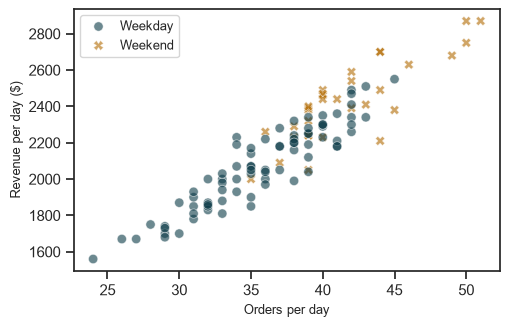

In [4]:
ax = sns.scatterplot(data=daily, x='orders', y='revenue',
                     hue='day_type', style='day_type',
                     s=45, alpha=0.6)
ax.set(xlabel='Orders per day', ylabel='Revenue per day ($)')
ax.legend(title='')
plt.show()

### Sizes and single dots

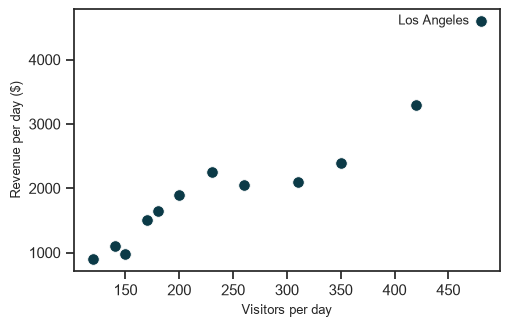

In [5]:
ax = sns.scatterplot(data=stores, x='visitors', y='daily_revenue',
                     s=70)
top = stores.loc[stores['daily_revenue'].idxmax()]
ax.annotate(top['store'], (top['visitors'], top['daily_revenue']),
            xytext=(-8, 0), textcoords='offset points',
            ha='right', va='center')
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

## 12.2 Lines with `lineplot()`

### One value per x

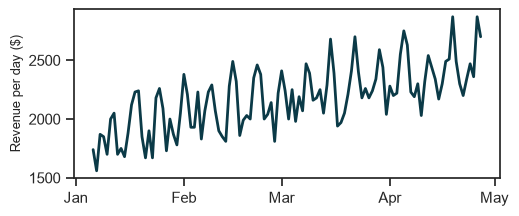

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 2.2))
sns.lineplot(data=daily, x='date', y='revenue', ax=ax)
ax.set(xlabel='', ylabel='Revenue per day ($)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.show()

In [7]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
daily['weekday'] = pd.Categorical(daily['date'].dt.strftime('%a'),
                                  categories=days, ordered=True)
by_day = daily.groupby('weekday')['revenue']
by_day.agg(['mean', 'count'])

,mean,count
weekday,,
Mon,2004.375,16
Tue,2021.250,16
Wed,2073.125,16
Thu,2033.125,16
Fri,2238.750,16
Sat,2495.625,16
Sun,2356.250,16


### The shaded band

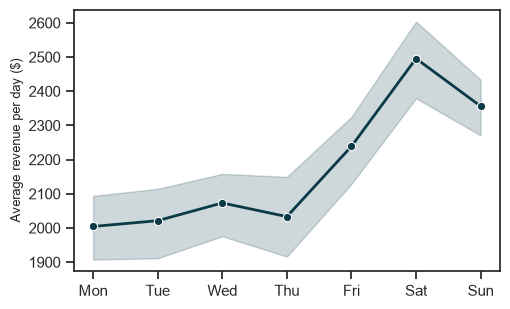

In [8]:
ax = sns.lineplot(data=daily, x='weekday', y='revenue',
                  marker='o', seed=0)
ax.set(xlabel='', ylabel='Average revenue per day ($)')
plt.show()

### `errorbar=`

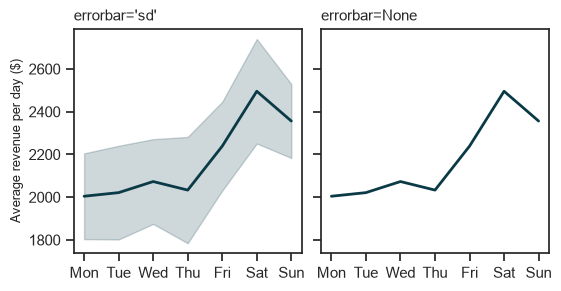

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.8), sharey=True,
                         layout='constrained')
sns.lineplot(data=daily, x='weekday', y='revenue',
             errorbar='sd', ax=axes[0])
sns.lineplot(data=daily, x='weekday', y='revenue',
             errorbar=None, ax=axes[1])
axes[0].set(title="errorbar='sd'", xlabel='',
            ylabel='Average revenue per day ($)')
axes[1].set(title='errorbar=None', xlabel='', ylabel='')
plt.show()

## 12.3 One Chart with `relplot()`

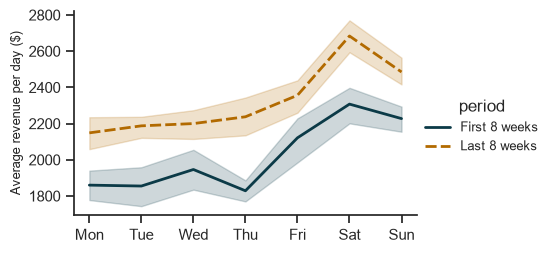

In [10]:
g = sns.relplot(data=daily, kind='line', x='weekday', y='revenue',
                hue='period', style='period', height=2.8,
                aspect=1.6, seed=0)
g.set_axis_labels('', 'Average revenue per day ($)')
plt.show()

## 12.4 Correlation

### `df.corr()`

In [11]:
stores.corr(numeric_only=True).round(2)

,visitors,daily_revenue,conversion
visitors,1.00,0.95,0.20
daily_revenue,0.95,1.00,0.48
conversion,0.20,0.48,1.00


In [12]:
r = stores['visitors'].corr(stores['daily_revenue'])
print(round(r, 2))

0.95


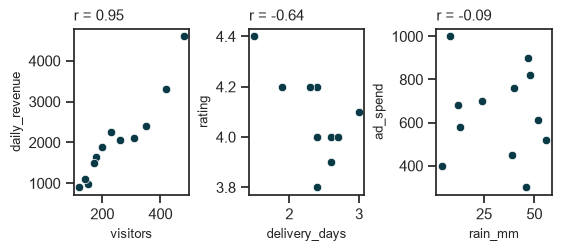

In [13]:
pairs = [(stores, 'visitors', 'daily_revenue'),
         (weekly, 'delivery_days', 'rating'),
         (weekly, 'rain_mm', 'ad_spend')]
fig, axes = plt.subplots(1, 3, figsize=(5.5, 2.4),
                         layout='constrained')
for ax, (table, x, y) in zip(axes, pairs):
    sns.scatterplot(data=table, x=x, y=y, color='#0b3a47', ax=ax)
    r = table[x].corr(table[y])
    ax.set(title=f'r = {r:.2f}')
plt.show()

### Outliers

In [14]:
weekly[['ad_spend', 'orders']].corr().round(2)

,ad_spend,orders
ad_spend,1.00,0.05
orders,0.05,1.00


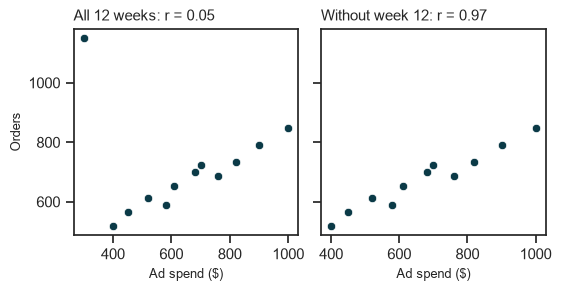

In [15]:
no_sale = weekly.drop(11)
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.8), sharey=True,
                         layout='constrained')
for ax, table, label in zip(axes, [weekly, no_sale],
                            ['All 12 weeks', 'Without week 12']):
    sns.scatterplot(data=table, x='ad_spend', y='orders',
                    color='#0b3a47', ax=ax)
    r = table['ad_spend'].corr(table['orders'])
    ax.set(title=f'{label}: r = {r:.2f}', xlabel='Ad spend ($)',
           ylabel='Orders')
plt.show()

## 12.5 Trend Lines with `regplot()` and `lmplot()`

### `sns.regplot()`

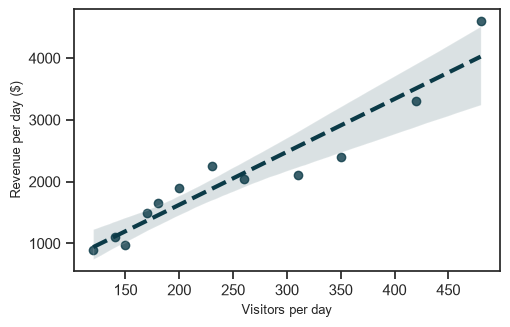

In [16]:
ax = sns.regplot(data=stores, x='visitors', y='daily_revenue',
                 seed=0)
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

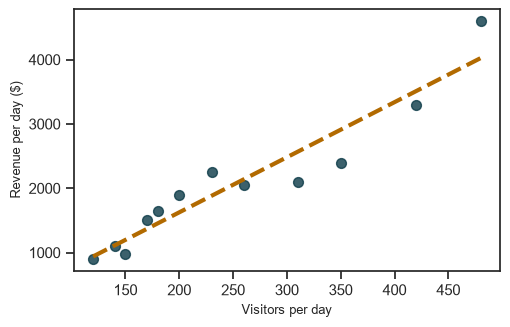

In [17]:
ax = sns.regplot(data=stores, x='visitors', y='daily_revenue',
                 ci=None, scatter_kws={'s': 50},
                 line_kws={'color': '#b26a00', 'linestyle': '--'})
ax.set(xlabel='Visitors per day', ylabel='Revenue per day ($)')
plt.show()

In [18]:
slope, intercept = np.polyfit(stores['visitors'],
                              stores['daily_revenue'], 1)
print(round(slope, 2), round(intercept))

8.56 -87


### `sns.lmplot()`

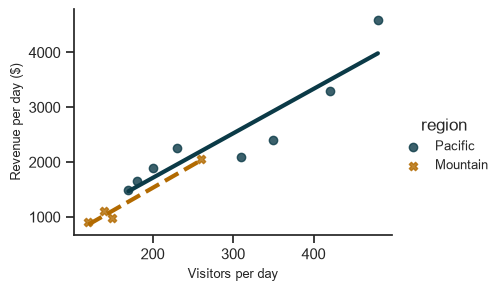

In [19]:
g = sns.lmplot(data=stores, x='visitors', y='daily_revenue',
               hue='region', markers=['o', 'X'], ci=None,
               height=3, aspect=1.4)
g.set_axis_labels('Visitors per day', 'Revenue per day ($)')
plt.show()